# Загрузка датасета

In [6]:
from sklearn.datasets import fetch_20newsgroups

data=fetch_20newsgroups(subset='all')
y=data.target

print(f"Всего документов: {len(data.data)}")
print(f"Кол-во категорий: {len(data.target_names)}")


Всего документов: 18846
Кол-во категорий: 20


# TFIDF эмбеддинг слов
использовал **TfidfVectorizer**, потому что при ручном эмбеддинге через циклы получилось около 207000 уникальных слов и сжимая до 50 и 100 основных признаков компьютер и колаб не справились

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer=TfidfVectorizer(max_df=0.75,min_df=5,stop_words='english')
X_tfidf=vectorizer.fit_transform(data.data)
print(f"Размерность TF-IDF: {X_tfidf.shape}")

Размерность TF-IDF: (18846, 34877)


# Уменьшение размерности и визуализация

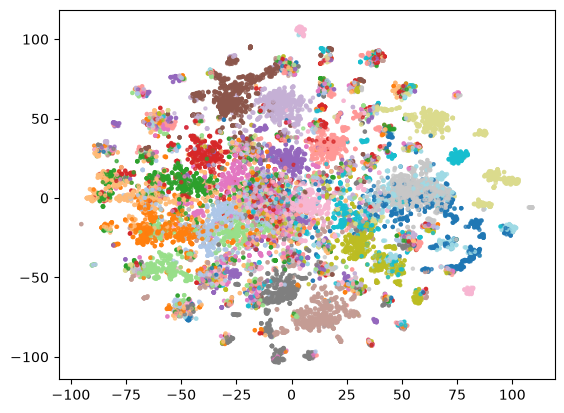

In [14]:
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

svd=TruncatedSVD(n_components=100)
x_svd=svd.fit_transform(X_tfidf)

tsne=TSNE(n_components=2)
x_tsne=tsne.fit_transform(x_svd)

plt.scatter(x_tsne[:, 0], x_tsne[:, 1], c=y, cmap='tab20', s=5, alpha=0.7)

# Клатеризация 
использовал: **KMeans**

проверял на: **silhouette_score**

In [17]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sopt=-1
kopt=-1
copt =None

for k in range(15,31):
    clf=KMeans(n_clusters=k,n_init=5)
    c=clf.fit_predict(x_svd)

    s=silhouette_score(x_svd,c)
    print(f"k={k}, Силуэт={s:.4f}")

    if s>sopt:
        sopt=s
        kopt=k
        copt=c

print(f"Оптимальное число кластеров: {kopt}")
print(f"Лучший силуэт: {sopt:.4f}")

k=15, Силуэт=0.0447
k=16, Силуэт=0.0450
k=17, Силуэт=0.0507
k=18, Силуэт=0.0378
k=19, Силуэт=0.0492
k=20, Силуэт=0.0466
k=21, Силуэт=0.0491
k=22, Силуэт=0.0536
k=23, Силуэт=0.0655
k=24, Силуэт=0.0680
k=25, Силуэт=0.0669
k=26, Силуэт=0.0476
k=27, Силуэт=0.0629
k=28, Силуэт=0.0687
k=29, Силуэт=0.0694
k=30, Силуэт=0.0461
Оптимальное число кластеров: 29
Лучший силуэт: 0.0694


# Сравнение с исходной разметкой датасета

In [18]:
from sklearn.metrics import adjusted_rand_score
ari = adjusted_rand_score(y, copt)
print(f"Adjusted Rand Index (ARI): {ari:.4f}")

Adjusted Rand Index (ARI): 0.1058


Text(0.5, 1.0, 'Результат KMeans (k=29)')

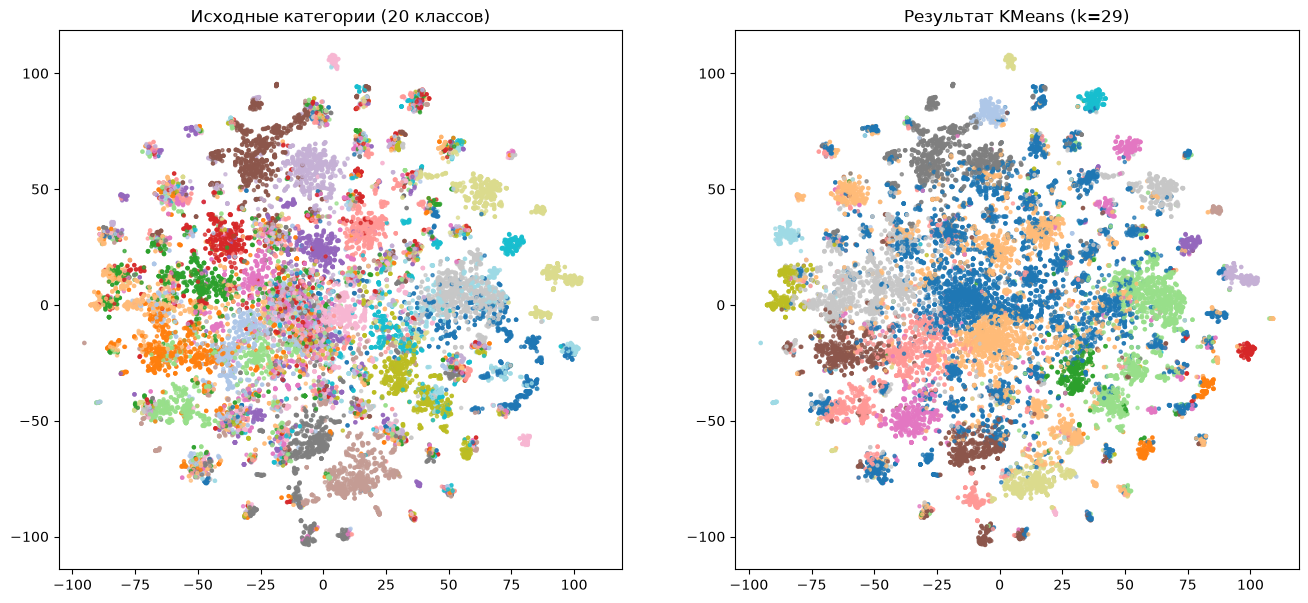

In [19]:
plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1)
plt.scatter(x_tsne[:, 0], x_tsne[:, 1], c=y, cmap='tab20', s=5, alpha=0.7)
plt.title("Исходные категории (20 классов)")

plt.subplot(1, 2, 2)
plt.scatter(x_tsne[:, 0], x_tsne[:, 1], c=copt, cmap='tab20', s=5, alpha=0.7)
plt.title(f"Результат KMeans (k={kopt})")

# Обсуждение

• **Низкий ARI**: В похожих темах используются одни и те же слова и метод считает только частоту слов, поэтому похожие темы слились в одну общую кучу. которую почти невозможно нормально разделить на 20 исходный категорий.

• **Почему K=29, а не 20**: Так как тексты перемешались в 1 большую кучу. Алгоритму KMeans было проще нарезать её на 29 случайных кусочков, чем угадать 20 реальных размытых тем.